# JSONBench result analysis

These charts compare throughput, successful-query runtimes and query outcomes across databases, scale factors and client counts.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from utilities import matrix_paths, prepare_charts

MATRIX_NAME = "ec2-large-results/paper-v1"  # Replace with the experiment name used in --output analysis/<name>.

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "jsonbench/matrix.py").exists())
sys.path.insert(0, str(ROOT / "notebooks"))


DATA, OUT = matrix_paths(MATRIX_NAME)
plt.rcParams.update(
    {
        "figure.dpi": 200,
        "savefig.dpi": 200,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "savefig.bbox": "tight",
    }
)
COLORS = {"mongodb": "#2166ac", "couchbase": "#b35806"}
LABELS = {"mongodb": "MongoDB", "couchbase": "Couchbase"}
SCALES = [10, 100, 200]
CLIENTS = [2, 4, 8, 16, 32, 64]


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=200)
    fig.savefig(OUT / f"{name}.pdf")
    plt.show()


In [2]:
charts = prepare_charts(DATA, SCALES, CLIENTS, COLORS)


## Throughput and runtime line charts

Lines show mean throughput and successful-query runtime across repetitions, with minimum–maximum shading, by scale factor and concurrent clients.


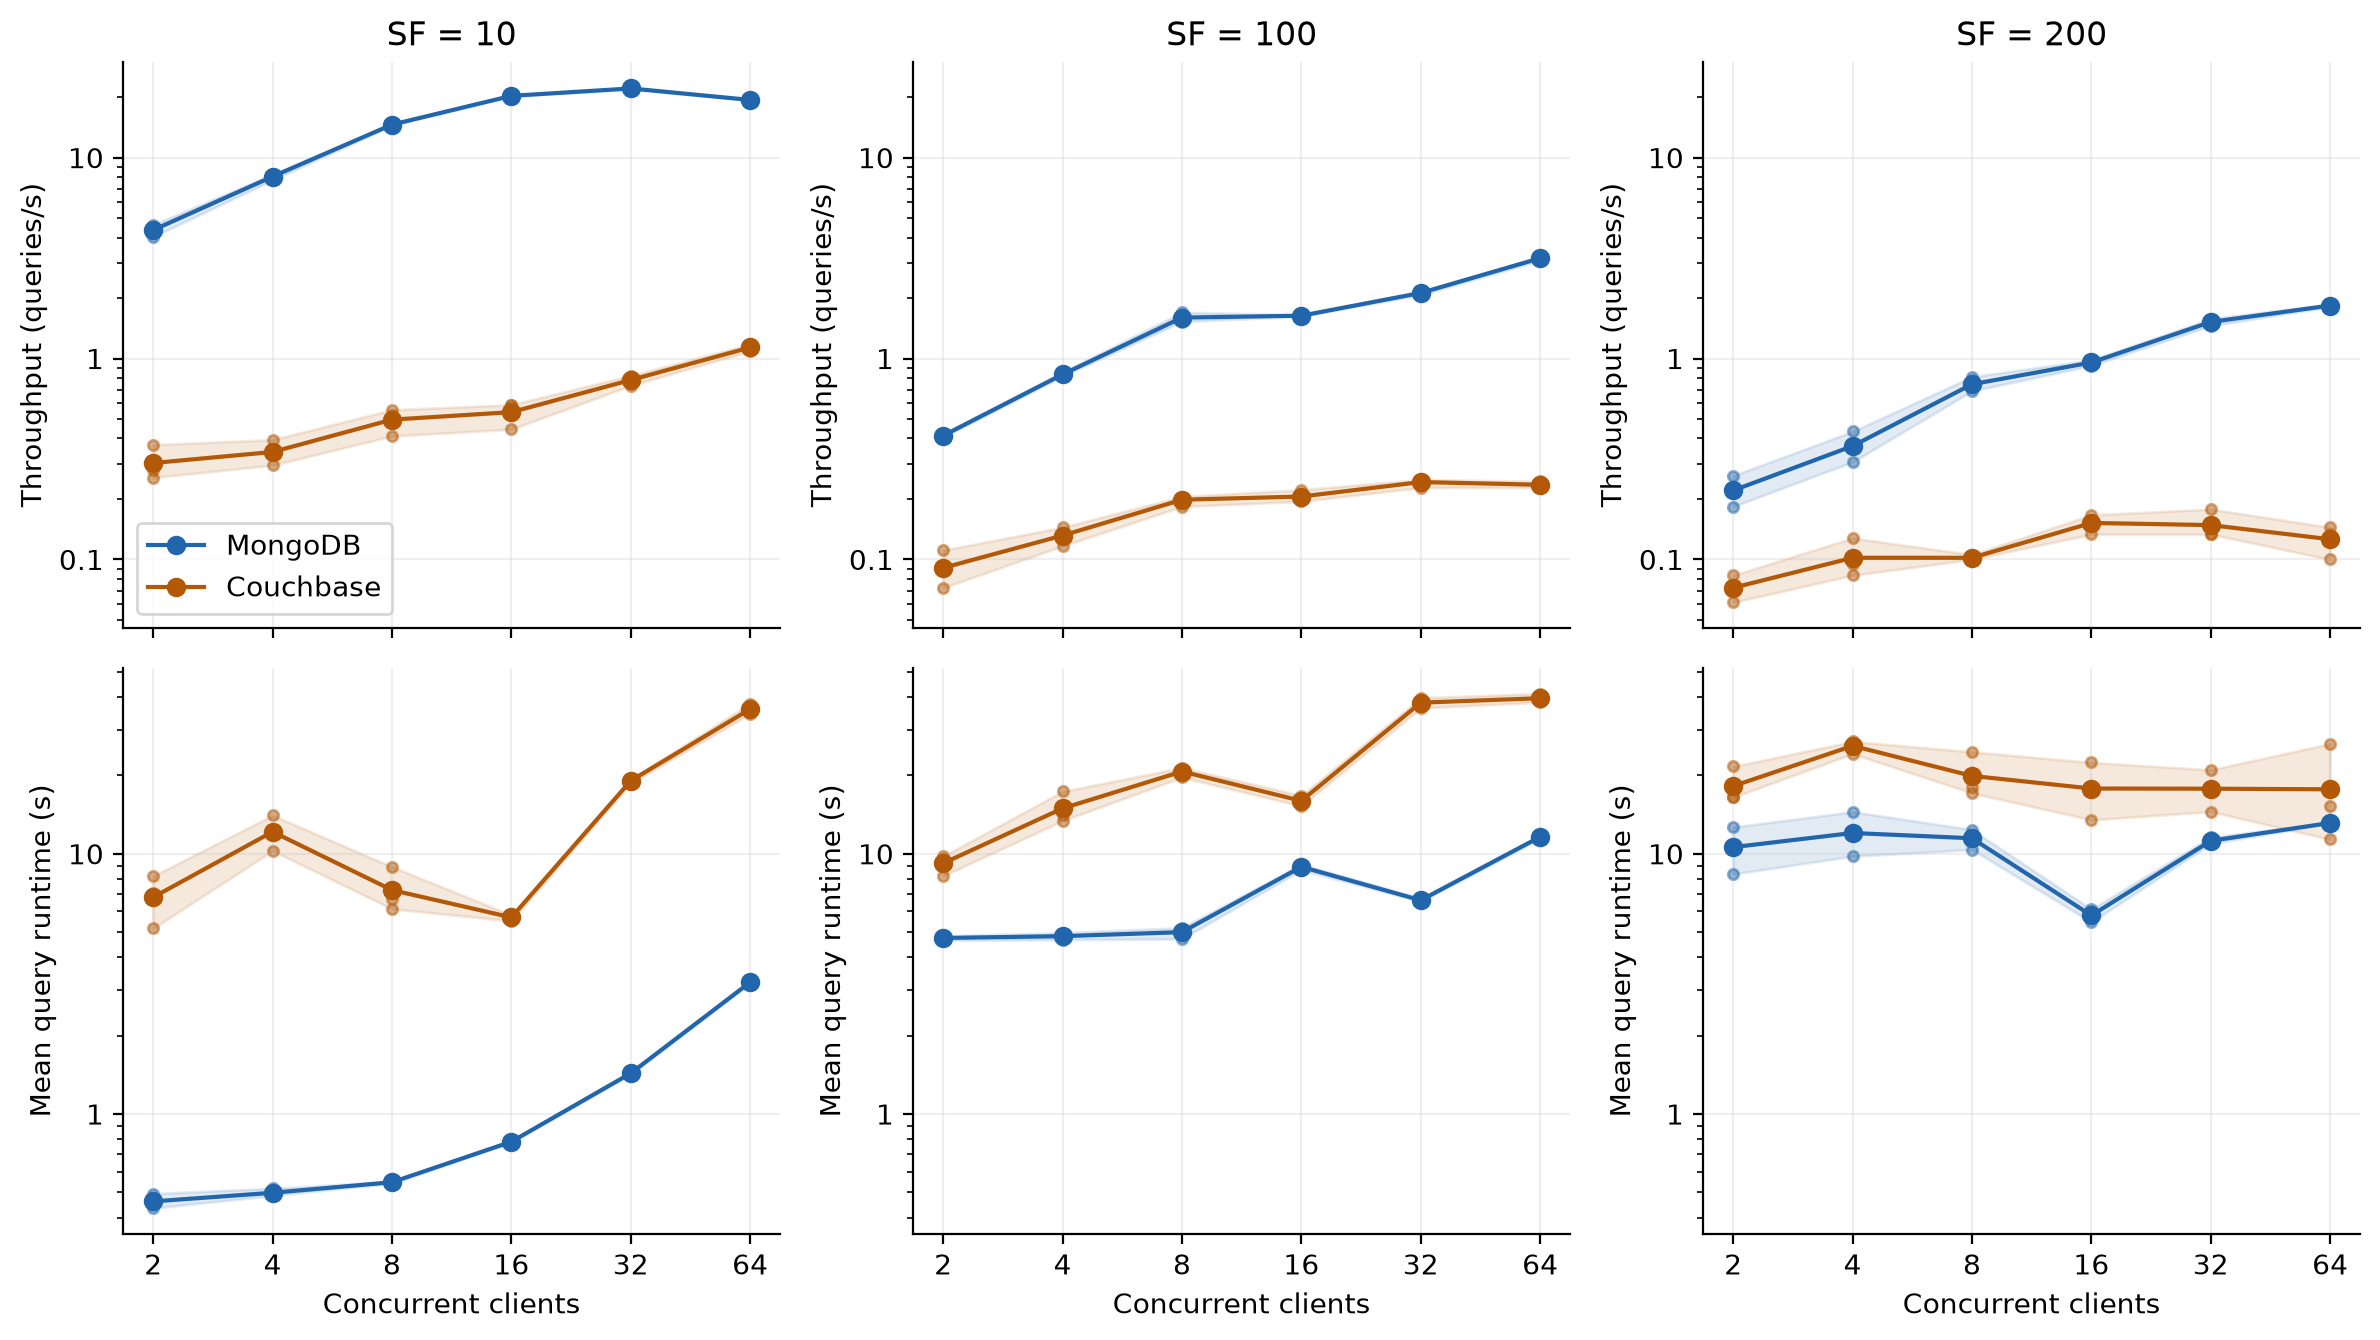

In [3]:
def draw(ax, sf, metric):
    for backend, color in COLORS.items():
        values = charts["lines"][backend, sf, metric]
        ax.plot(values["x"], values["mean"], marker="o", color=color, label=LABELS[backend])
        ax.fill_between(values["x"], values["low"], values["high"], color=color, alpha=0.13)
        ax.scatter(values["point_x"], values["point_y"], color=color, alpha=0.5, s=14)
    ax.grid(alpha=0.2)


fig, axes = plt.subplots(2, 3, figsize=(12, 6.8), sharex=True, sharey="row")
for j, sf in enumerate(SCALES):
    for i, metric in enumerate(["throughput_qps", "successful_runtime_s"]):
        ax = axes[i, j]
        draw(ax, sf, metric)
        ax.set_xscale("log", base=2)
        ax.set_xticks(CLIENTS, labels=CLIENTS)
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:g}"))
        if i == 0:
            ax.set_title(f"SF = {sf}")
        else:
            ax.set_xlabel("Concurrent clients")
for ax in axes[0]:
    ax.set_ylabel("Throughput (queries/s)")
    ax.tick_params(axis="y", labelleft=True)
for ax in axes[1]:
    ax.set_ylabel("Mean query runtime (s)")
    ax.tick_params(axis="y", labelleft=True)
axes[0, 0].legend()
fig.tight_layout()
save(fig, "clients_by_scale")


## Normalized outcome bar charts

Bars show mean repetition-level percentages of successes, errors and timeouts by database, scale factor and client count.


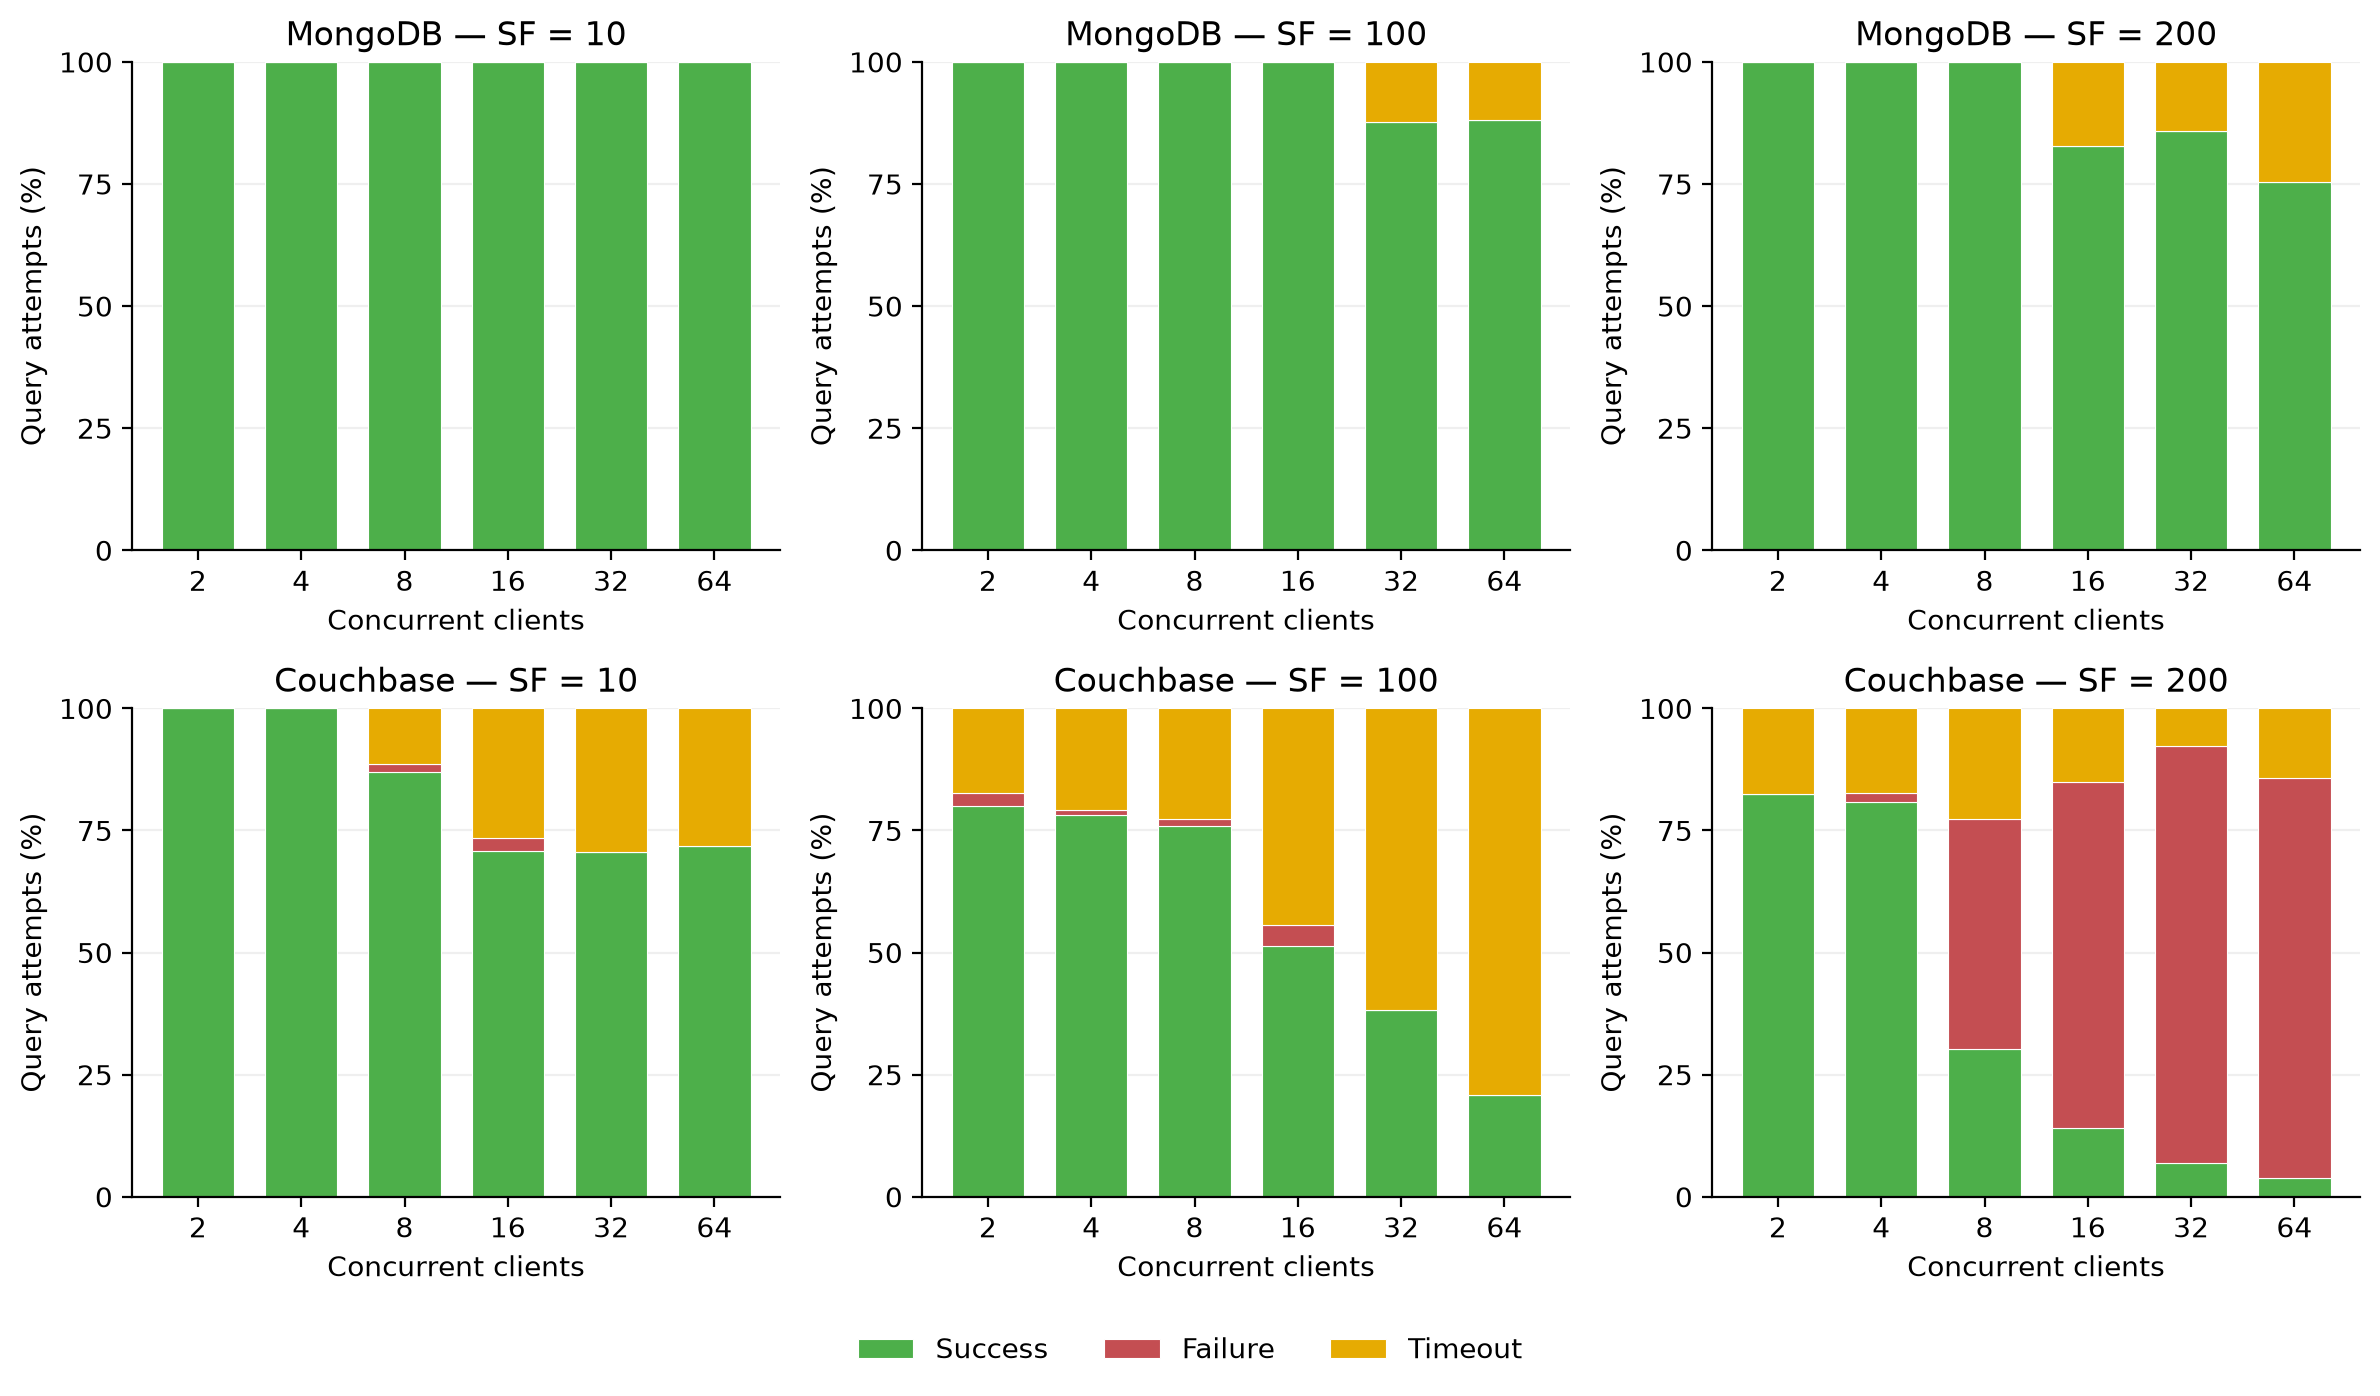

In [4]:
outcome_colors = {"Success": "#4daf4a", "Failure": "#c44e52", "Timeout": "#e6ab02"}
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
x = np.arange(len(CLIENTS))
for i, backend in enumerate(COLORS):
    for j, sf in enumerate(SCALES):
        ax = axes[i, j]
        for label, color in outcome_colors.items():
            heights, bottom = charts["outcomes"][backend, sf][label]
            ax.bar(x, heights, 0.7, bottom=bottom, color=color, edgecolor="white", linewidth=0.4, label=label)
        ax.set_title(f"{LABELS[backend]} — SF = {sf}")
        ax.set_xticks(x, labels=CLIENTS)
        ax.set_xlabel("Concurrent clients")
        ax.set_ylabel("Query attempts (%)")
        ax.set_ylim(0, 100)
        ax.set_yticks([0, 25, 50, 75, 100])
        ax.tick_params(axis="both", labelleft=True, labelbottom=True)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0), frameon=False)
fig.tight_layout(rect=(0, 0.055, 1, 1))
save(fig, "query_outcomes_normalized")


## Failure-rate heatmaps

Heatmaps show mean percentages of errors and timeouts by scale factor and concurrent clients.


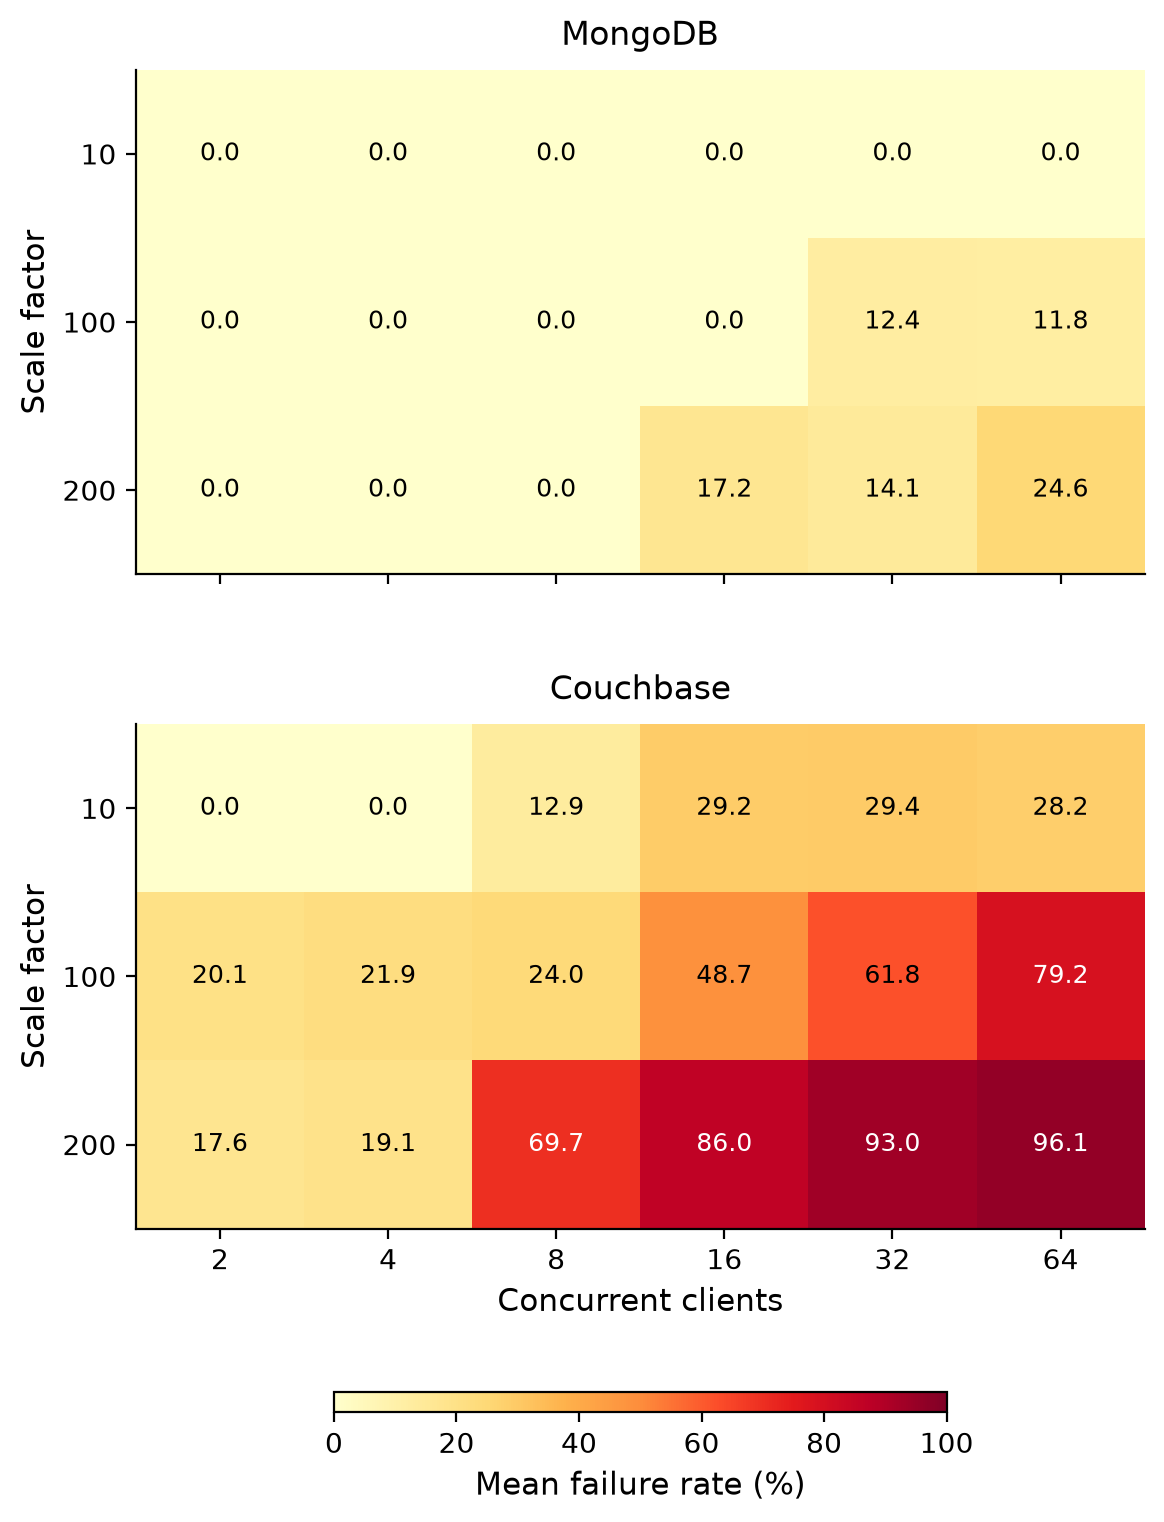

In [5]:
# Compact vertical version for a single paper column.
# Cell values are percentages; the shared colorbar supplies the unit.
fig, axes = plt.subplots(2, 1, figsize=(6, 7.5), layout="constrained", sharex=True, sharey=True)
fig.get_layout_engine().set(hspace=0.12)
for ax, backend in zip(axes, COLORS):
    grid = charts["heatmaps"][backend]
    im = ax.imshow(grid, vmin=0, vmax=100, cmap="YlOrRd", aspect="equal")
    for i in range(len(SCALES)):
        for j in range(len(CLIENTS)):
            value = grid[i, j]
            ax.text(
                j,
                i,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if value > 65 else "black",
            )
    ax.set_xticks(range(len(CLIENTS)), labels=CLIENTS)
    ax.set_yticks(range(len(SCALES)), labels=SCALES)
    ax.tick_params(labelsize=10)
    ax.set_title(LABELS[backend], fontsize=12, pad=9)
    ax.set_ylabel("Scale factor", fontsize=11)
axes[-1].set_xlabel("Concurrent clients", fontsize=11)
colorbar = fig.colorbar(im, ax=axes, orientation="horizontal", pad=0.06, fraction=0.055, shrink=0.57, aspect=30)
colorbar.set_label("Mean failure rate (%)", fontsize=11)
colorbar.ax.tick_params(labelsize=10)
save(fig, "failure_heatmaps_vertical")


## Query runtime box plots

Boxes show successful-query runtime quartiles, medians and 5th–95th percentile whiskers by query and database, pooling clients and repetitions for each scale factor and overall.


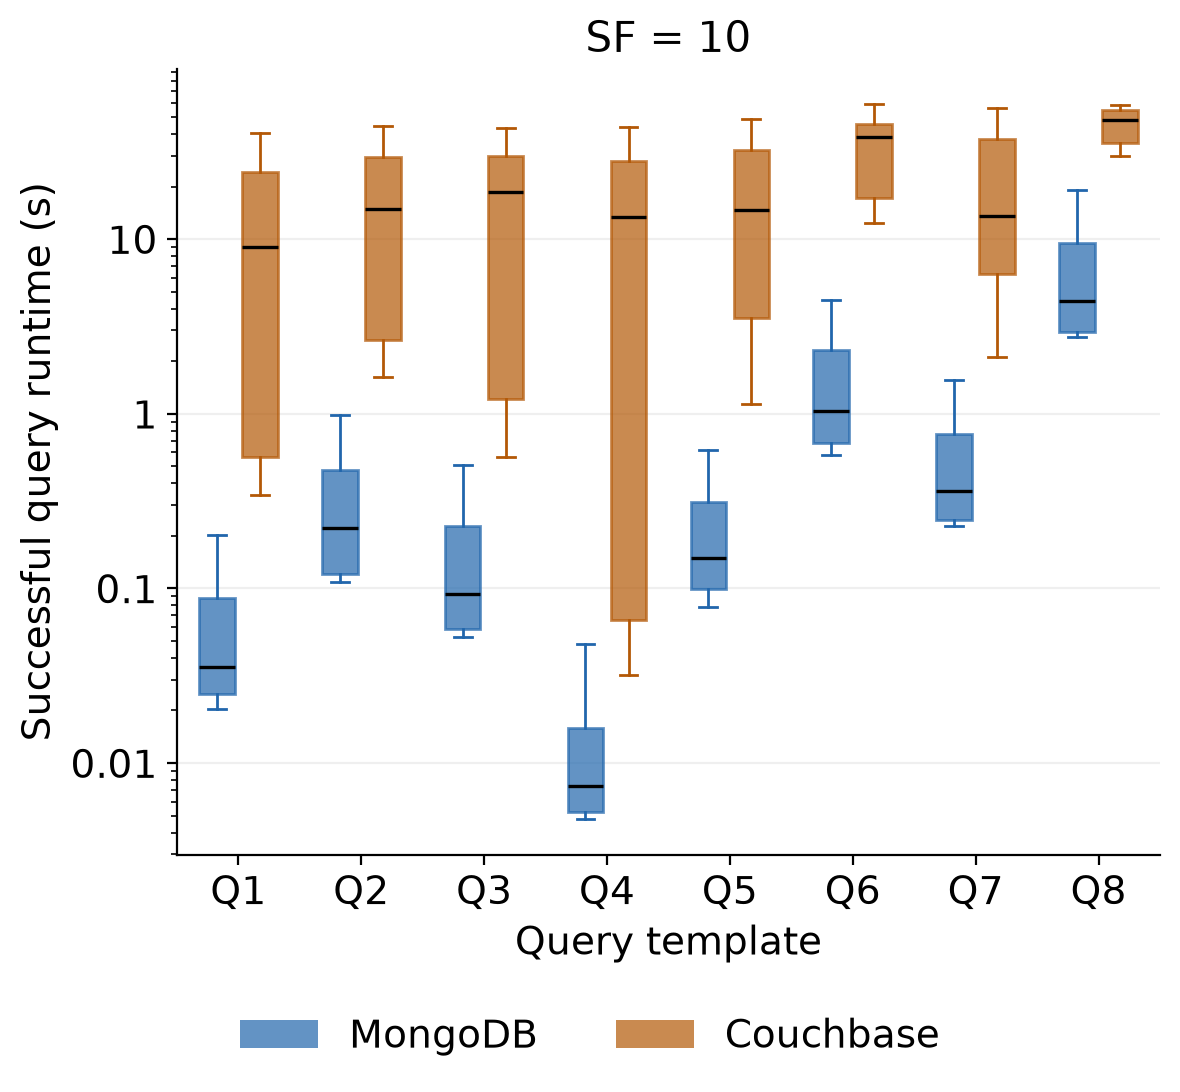

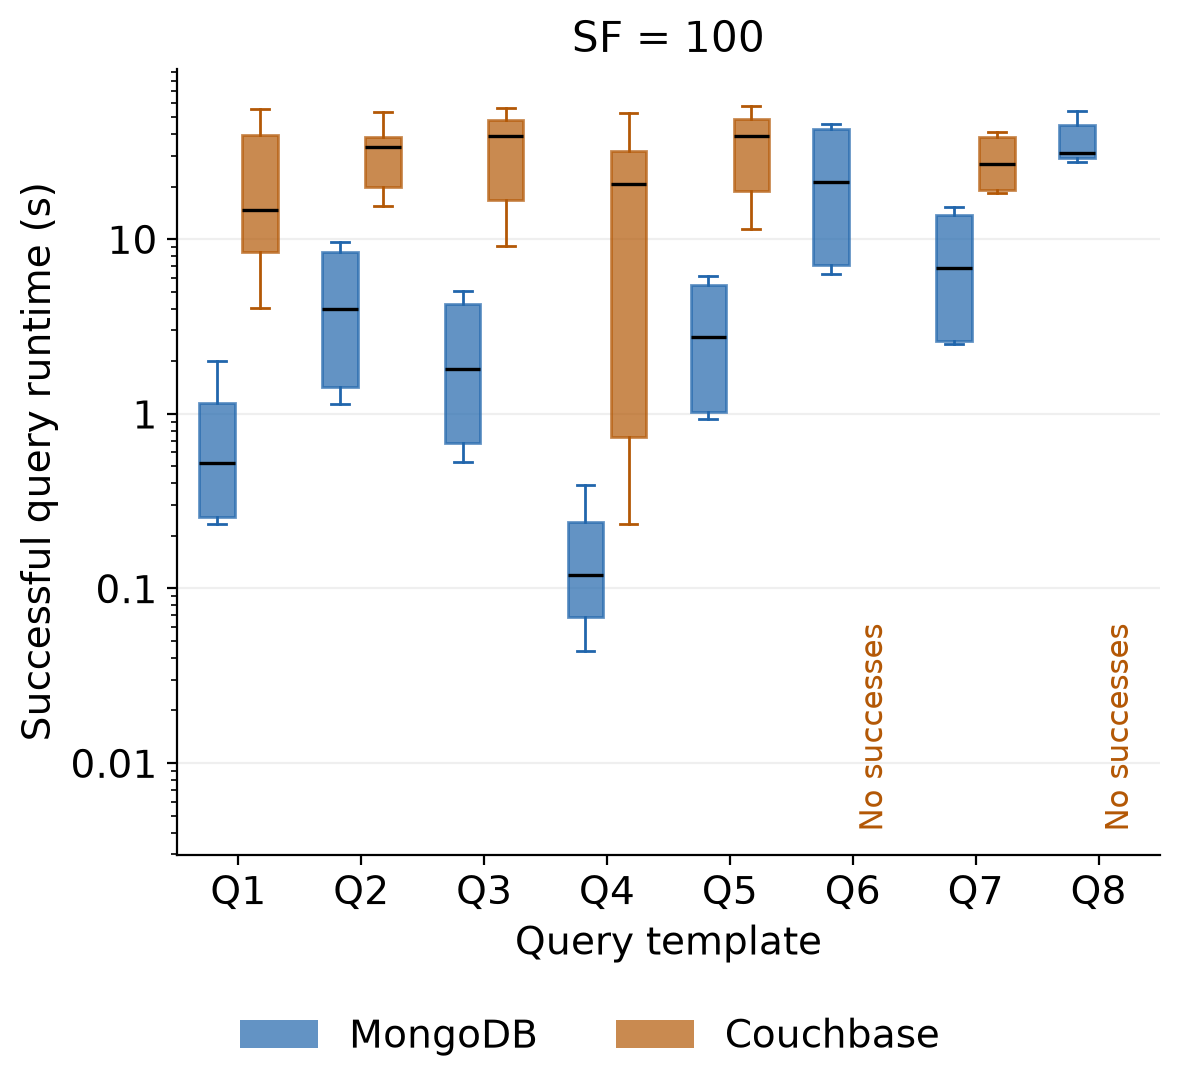

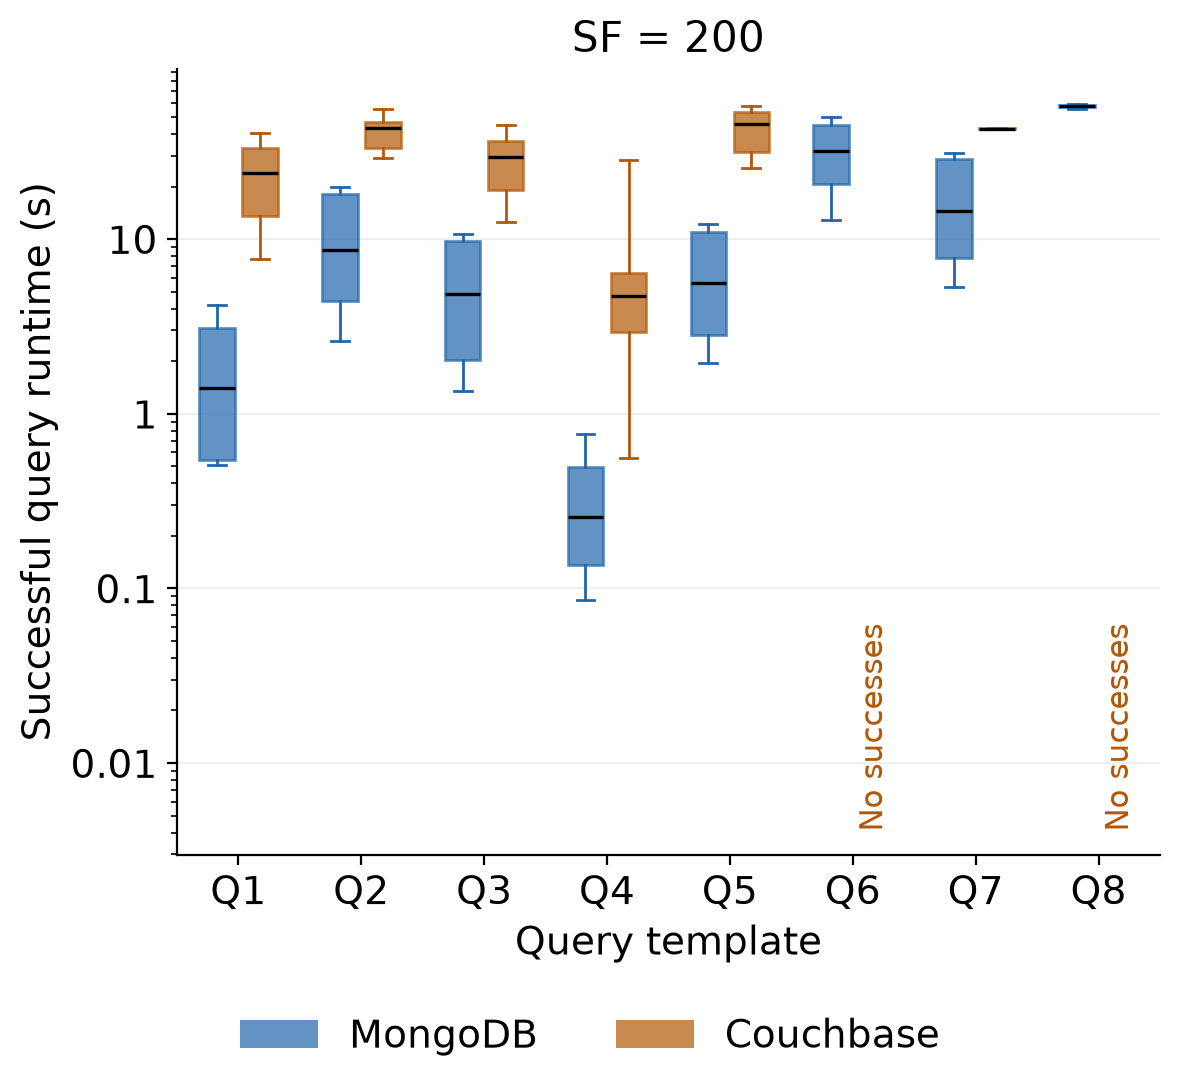

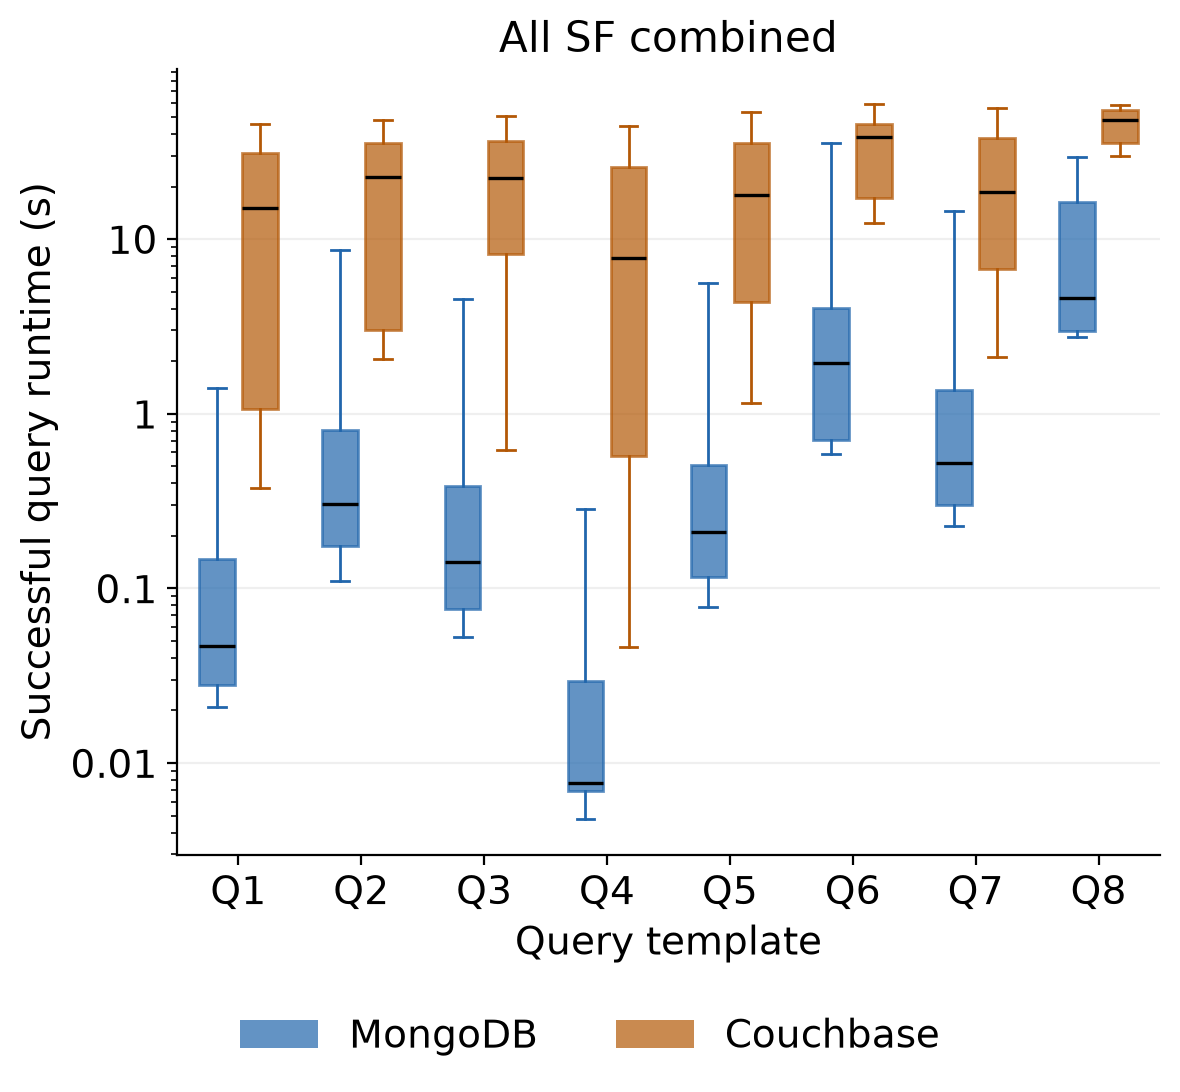

In [6]:
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

spread_figures = []
for sf in [10, 100, 200, None]:
    fig, ax = plt.subplots(figsize=(6, 5.6))
    ax.set_box_aspect(0.8)
    spread_figures.append((sf, fig, ax))
    for b, (backend, color) in enumerate(COLORS.items()):
        for q in range(1, 9):
            stats = charts["boxes"][backend, sf, q]
            pos = q + (b - 0.5) * 0.35
            if stats is not None:
                ax.bxp(
                    stats,
                    positions=[pos],
                    widths=0.29,
                    patch_artist=True,
                    showfliers=False,
                    manage_ticks=False,
                    boxprops=dict(facecolor=color, edgecolor=color, alpha=0.7),
                    whiskerprops=dict(color=color),
                    capprops=dict(color=color),
                    medianprops=dict(color="black", linewidth=1.2),
                )
            else:
                ax.text(
                    pos,
                    0.03,
                    "No successes",
                    rotation=90,
                    ha="center",
                    va="bottom",
                    fontsize=11,
                    color=color,
                    transform=ax.get_xaxis_transform(),
                )
    ax.set_title("All SF combined" if sf is None else f"SF = {sf}", fontsize=15)
    ax.set_xticks(range(1, 9), [f"Q{q}" for q in range(1, 9)])
    ax.set_xlim(0.5, 8.5)
    ax.set_xlabel("Query template", fontsize=14)
    ax.set_ylabel("Successful query runtime (s)", fontsize=14)
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
    ax.tick_params(labelleft=True, labelsize=14)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
# Use identical limits across the independent charts for direct comparison.
shared_limits = (
    min(ax.get_ylim()[0] for _, _, ax in spread_figures),
    max(ax.get_ylim()[1] for _, _, ax in spread_figures),
)
for sf, fig, ax in spread_figures:
    ax.set_ylim(*shared_limits)
    fig.legend(
        [Patch(facecolor=c, alpha=0.7) for c in COLORS.values()],
        [LABELS[b] for b in COLORS],
        loc="lower center",
        ncol=2,
        frameon=False,
        fontsize=14,
    )
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    suffix = "all_sf" if sf is None else f"sf{sf}"
    fig.savefig(OUT / f"query_runtime_spread_{suffix}.png", dpi=200)
    fig.savefig(OUT / f"query_runtime_spread_{suffix}.pdf")
    display(fig)
    plt.close(fig)


## Query outcome count bar charts

Stacked bars compare success, error and timeout counts per query between databases, pooling clients and repetitions for each scale factor and overall.


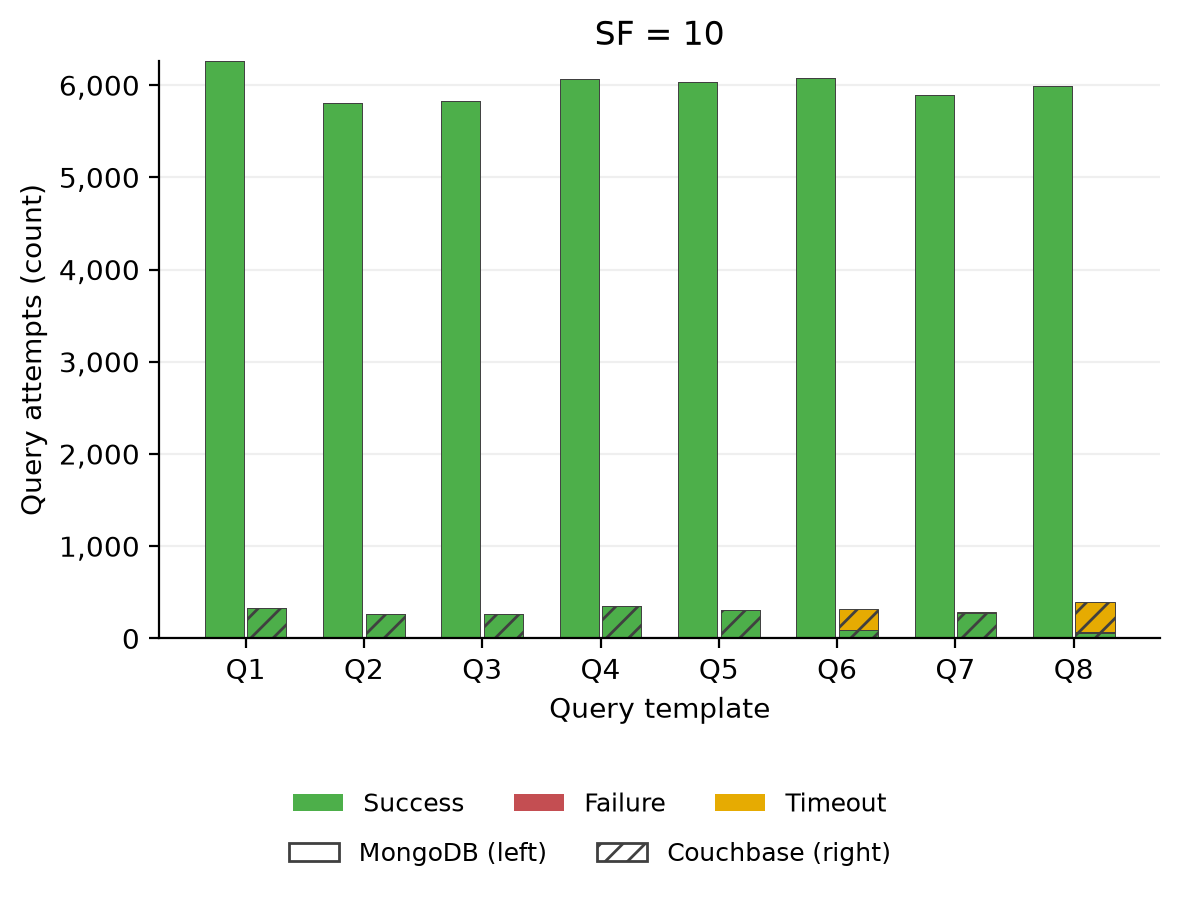

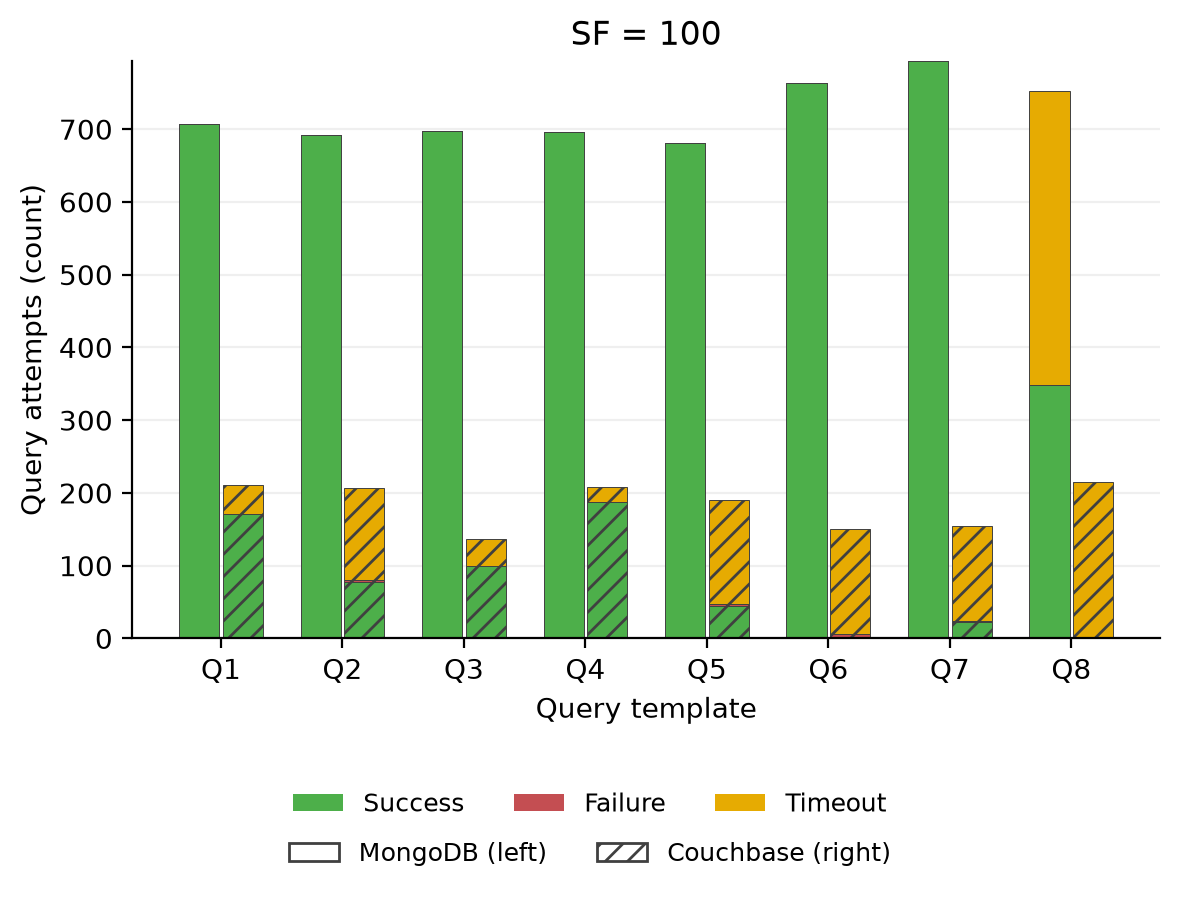

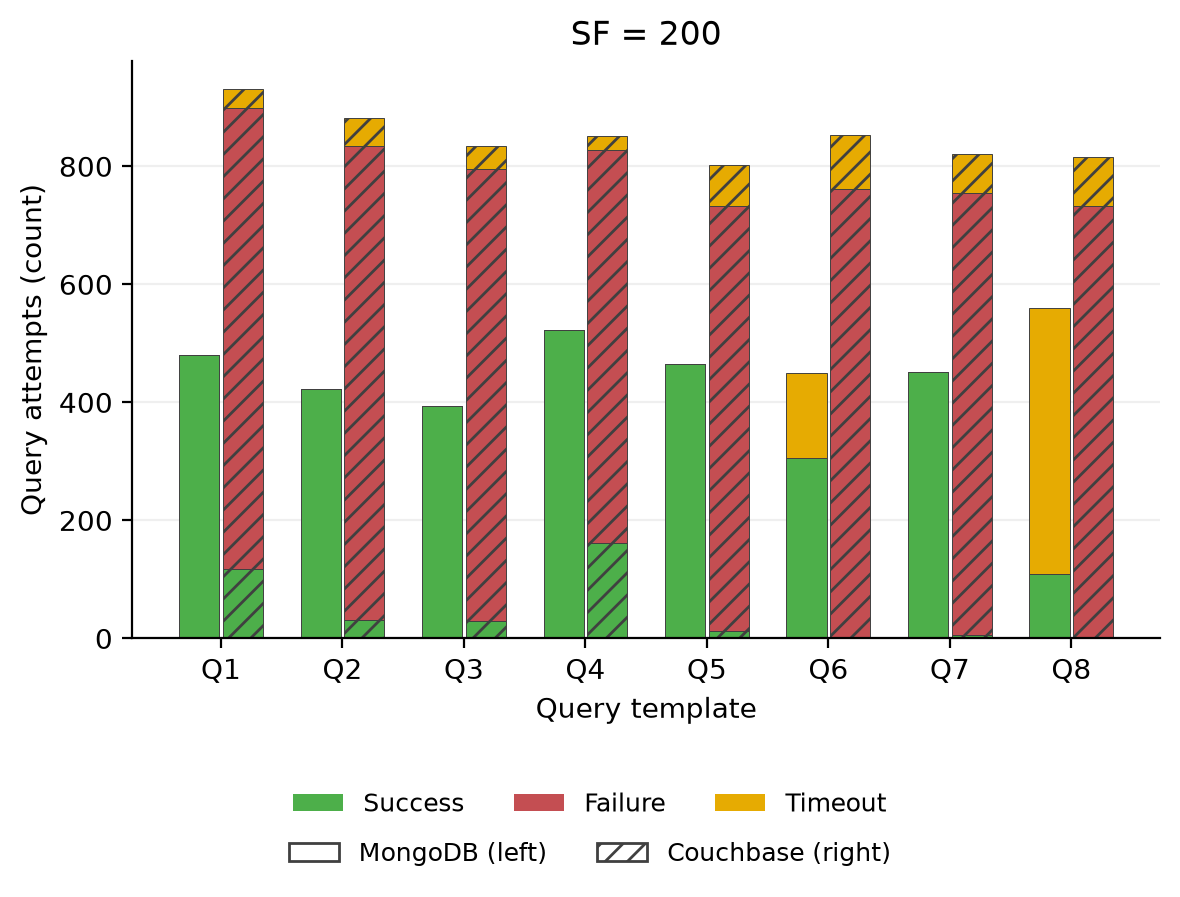

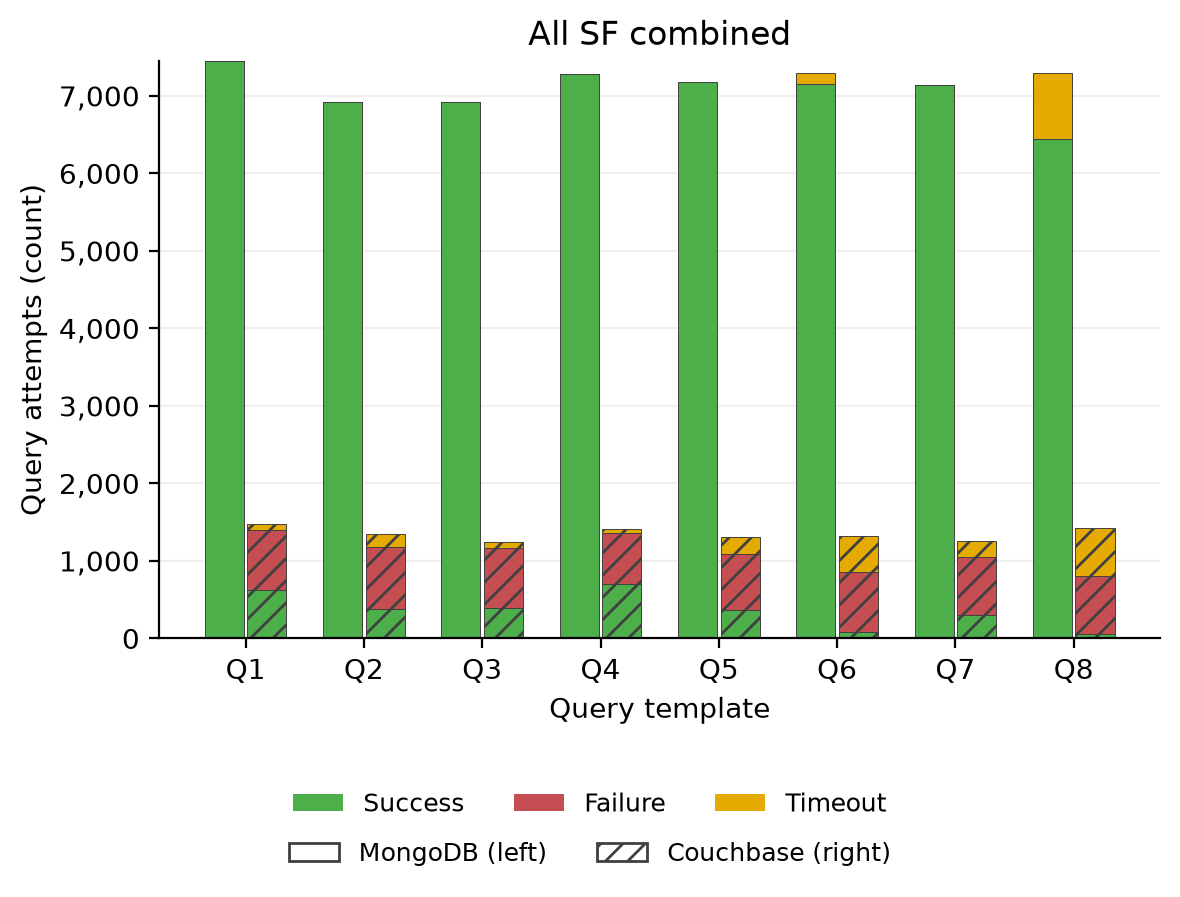

In [7]:
from matplotlib.ticker import StrMethodFormatter

status_colors = {"success": "#4daf4a", "error": "#c44e52", "timeout": "#e6ab02"}
status_labels = {"success": "Success", "error": "Failure", "timeout": "Timeout"}
outcome_figures = []
for sf in [10, 100, 200, None]:
    fig, ax = plt.subplots(figsize=(6, 4.5))
    outcome_figures.append((sf, fig))
    for b, backend in enumerate(COLORS):
        x = np.arange(1, 9) + (b - 0.5) * 0.36
        for status, color in status_colors.items():
            values, bottom = charts["counts"][backend, sf][status]
            ax.bar(
                x,
                values,
                width=0.33,
                bottom=bottom,
                color=color,
                hatch="///" if backend == "couchbase" else None,
                edgecolor="0.25",
                linewidth=0.35,
            )
    ax.set_title("All SF combined" if sf is None else f"SF = {sf}")
    ax.set_xticks(range(1, 9), [f"Q{q}" for q in range(1, 9)])
    ax.set_xlabel("Query template")
    ax.set_ylabel("Query attempts (count)")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
legend = [Patch(facecolor=color, label=status_labels[status]) for status, color in status_colors.items()]
legend += [
    Patch(facecolor="white", edgecolor="0.25", label="MongoDB (left)"),
    Patch(facecolor="white", edgecolor="0.25", hatch="///", label="Couchbase (right)"),
]
for sf, fig in outcome_figures:
    fig.legend(handles=legend[:3], loc="lower center", bbox_to_anchor=(0.5, 0.055), ncol=3, frameon=False, fontsize=9)
    fig.legend(handles=legend[3:], loc="lower center", bbox_to_anchor=(0.5, 0), ncol=2, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, 0.15, 1, 1))
    suffix = "all_sf" if sf is None else f"sf{sf}"
    fig.savefig(OUT / f"query_outcome_counts_{suffix}.png", dpi=200)
    fig.savefig(OUT / f"query_outcome_counts_{suffix}.pdf")
    display(fig)
    plt.close(fig)
